# Inference of ABP Velocity
... using approximate Brownian Bridges as a sampling accelerator



# Ground Truths

In [1]:
_GT_DR_  = 0.5
_GT_V_   = 1.
_DT_OBS_ = 1.0
_DT_     = 0.1
_N_OBS_  = 30
_SIG_OBS_ = 3e-1
_FUTURES_ = 3

# Imports

In [2]:
from numba import njit, prange
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import Tensor as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions.normal import Normal
from tqdm import tqdm
from itertools import zip_longest
from ppolib import PPO_Agent
import pickle
import os
from bootstrap_mean_std import bootstrap_mean_std
import scrapbook as sb
from scipy.optimize import curve_fit

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.ndimage import zoom, gaussian_filter
from scipy.optimize import curve_fit
from tqdm.notebook import tqdm
from random import choice
from inference_tools_ppo import ParticleFilter, crng, HilbertSorter, ConditionedBridge, bridge_logl, ZeroBasedRNG, draw_bridge_level, draw_empirical_ellipsoid, kl_divergence_from_samples
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm

sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

torch.autograd.set_detect_anomaly(True)

# SDE Equation of Motion

In [3]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    output_bridge_parameters = params.get('output_bridge_parameters', False)
    use_bridges = params['use_bridges']
    use_tqdm = params.get('use_tqdm', False)
    target_shift_P = params.get('target_shift_PHI', 0.)
    target_slope_P = params.get('target_slope_PHI', 0.)
    spread0 = params['bridge_spread0'] if params['use_spread'] else 0.
    spread1 = params['bridge_spread1'] if params['use_spread'] else 0.
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    logDr = params['logDr']
    logv  = params['logv']
    Dr    = np.exp(logDr)
    v     = np.exp(logv)
    _id = params.get('id', -1)
    dt  = params['dt']
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if use_bridges:
        slope_factor = 1 / (np.sqrt(2 * Dr * dt_))
        shift_factor = 1 / (np.sqrt(2 * Dr * dt_) * v * dt_)
        
        slopeP = (target_slope_P + spread1 * np.random.randn(n_parts)) * slope_factor
        shiftP = (target_shift_P + spread0 * np.random.randn(n_parts)) * shift_factor 
        
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG)
        
        logl = bridge_logl(np.mean(shiftP), np.mean(slopeP), n_steps + 1) - 2 * np.log(v * np.sqrt(2*Dr*dt))
        reward_logl = bridge_logl(np.mean(shiftP), np.mean(slopeP), n_steps + 1) - bridge_logl(0., 0., n_steps + 1)
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = ddP
        
    else:
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, n_steps), corr=0)
        logl = 0
        reward_logl = 0

    if use_tqdm:  
        R_ = tqdm(range(n_steps))
    else:
        R_ = range(n_steps)
        
    for k in R_:

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx*v, dy*v, np.zeros_like(dx)], axis=1)

        X[..., -1] += np.sqrt(dt_) * w[..., k] * np.sqrt(2 * Dr)
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=logl, reward_logl=reward_logl, per_particle_streams=dict())
    
    if output_hires:
        res_dict['per_particle_streams']['hires'] = np.stack(hires, -1)

    if output_bridge_parameters:
        ww = np.cumsum(w, axis=1)
        www = np.cumsum(ww, axis=1)
        bridge_confs = np.stack([ww[:, None, [-1],], www[:, None, [-1],]], axis=1)
        res_dict['per_particle_streams']['bridge_slope'] = bridge_confs

    return res_dict

In [4]:
def abp_run_simple(X0=np.zeros((1, 3)),
                   dt=1e-1, Tout=np.linspace(0, 1, 11),
                   params=None
                  ):   
    
    if params is None:
        params = dict(RNG=crng(),
                      Dr = 1e-2,
                      v = 1,
                      dt = dt,
                      output_hires=True,
                      BridgeGen=bridge_gen,
                      use_tqdm = False,
                     )

    x = [X0[:, 0]]
    y = [X0[:, 1]]
    phi = [X0[:, 2]]
    Told = 0
    for Tmax in Tout:
        params['RNG'].reroll(0)
        sim_res = abp_sde(Told, Tmax, np.stack([x[-1], y[-1], phi[-1]]).T, params)
        Told = Tmax
        x.append(sim_res['X1'][:, 0])
        y.append(sim_res['X1'][:, 1])
        phi.append(sim_res['X1'][:, 2])

    x = np.stack(x[1:])
    y = np.stack(y[1:])
    
    return dict(x=x, y=y)

# Data Generation

Generating the test data, with perfectly straight movement

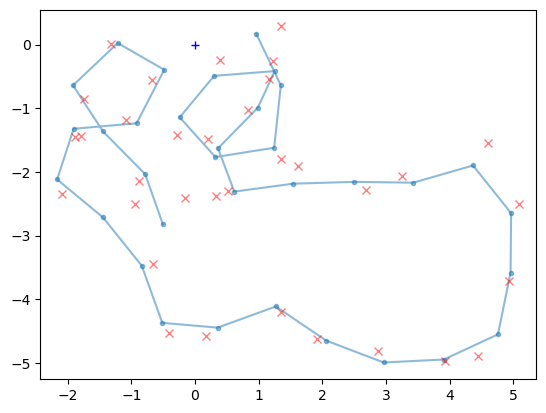

In [5]:
N = 1
dt = _DT_
v = _GT_V_
Tmax = _DT_OBS_ * (_N_OBS_ + _FUTURES_ + 1)

X0 = np.random.uniform(size=(N,3)) * [0, 0, 0]
Tout=np.linspace(_DT_OBS_, Tmax, _N_OBS_ + _FUTURES_ + 1)

# Using Seeds 1234, 12345, 123456, etc.
params = dict(RNG=crng(seed=None),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              use_tqdm = False,
              target_slope_PHI=0.0,
              target_shift_PHI=0,
              use_bridges = False,
              output_bridge_parameters = True,
              use_spread = False,
             )

res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
OBS_X = GT_X + np.random.normal(scale = _SIG_OBS_, size=GT_X.shape) / np.sqrt(2)
OBS_Y = GT_Y + np.random.normal(scale = _SIG_OBS_, size=GT_Y.shape) / np.sqrt(2)

plt.plot(GT_X, GT_Y, '.-', alpha=0.5)
plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
plt.plot([0], [0], '+b')
plt.gca().axis('equal')
plt.show()

# INFERENCE

## Setup

In [6]:
params = dict(RNG=crng(),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              dt = _DT_,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = _SIG_OBS_,
              output_hires=False,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              HilbertSort_useObservationCenter = False,
              observation_parameters = [],
              reward_range = 1e-15,
              action_range0 = 1.0,
              action_range1 = 1.0,
              deterministic_agent = False,
              provide_absolute_orientation = False,
              provide_absolute_x_location = False,
              provide_absolute_y_location = False,
              provide_swarm_polarity = False,
              base_on_last_observation = False,
              use_bridge_offsets = False,
              rotate_observations_to_swarm = True,
              use_bridges = False,
              output_bridge_parameters = True,
             )

def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -((X - Y) / sigma) ** 2, axis=1)

## Data Preparation and Augementation

In [7]:
Y0 = [dict(T=T,
           Y=np.array([float(X[0]), float(Y[0]), np.nan]),
          )
      for T, X, Y in zip(Tout, OBS_X, OBS_Y)
     ]

# Augment each observation with the offsets to future target points

for y in Y0:
    y['future_x'] = [y['Y'][0]]
    y['future_y'] = [y['Y'][1]]
    
for offset in range(1, _FUTURES_ + 1):    
    for y1, y2 in zip(Y0, Y0[offset:]):
        y1['future_x'].append(y2['Y'][0])
        y1['future_y'].append(y2['Y'][1])

params['futures'] = _FUTURES_
Y0 = Y0[:_N_OBS_] # Cut of the last observations that don't have enough futures

## Prerun the Particle Filter

Run the naive Particle Filter to estimate the posterior density.

In [8]:
N_parts_test = 4000
X0_test = (np.zeros((N_parts_test, 3)))
params['RNG'] = crng()
params['use_bridges'] = False
params['output_bridge_parameters'] = True
params['use_spread'] = False

v_offset_min = 0.75
v_offset_max = 1.25

len_test  = []
rew_test  = []
logl_test = []
action0_test = []
action1_test = []

v_offsets = np.linspace(v_offset_min, v_offset_max, 300)

for v_off in tqdm(v_offsets):
        params['sigma_observation'] = _SIG_OBS_
        params['logv'] = np.log(_GT_V_*v_off)
        params['RNG'].reroll()
        res = ParticleFilter(abp_logl, abp_sde, X0_test, Y0, params)
        action0_test.append(res['streams']['bridge_slope'].squeeze()[0, :])
        action1_test.append(res['streams']['bridge_slope'].squeeze()[1, :])
        logl_test.append([v_off, res['logl']])

action0_test = np.stack(action0_test)
action1_test = np.stack(action1_test)

  0%|          | 0/300 [00:00<?, ?it/s]

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


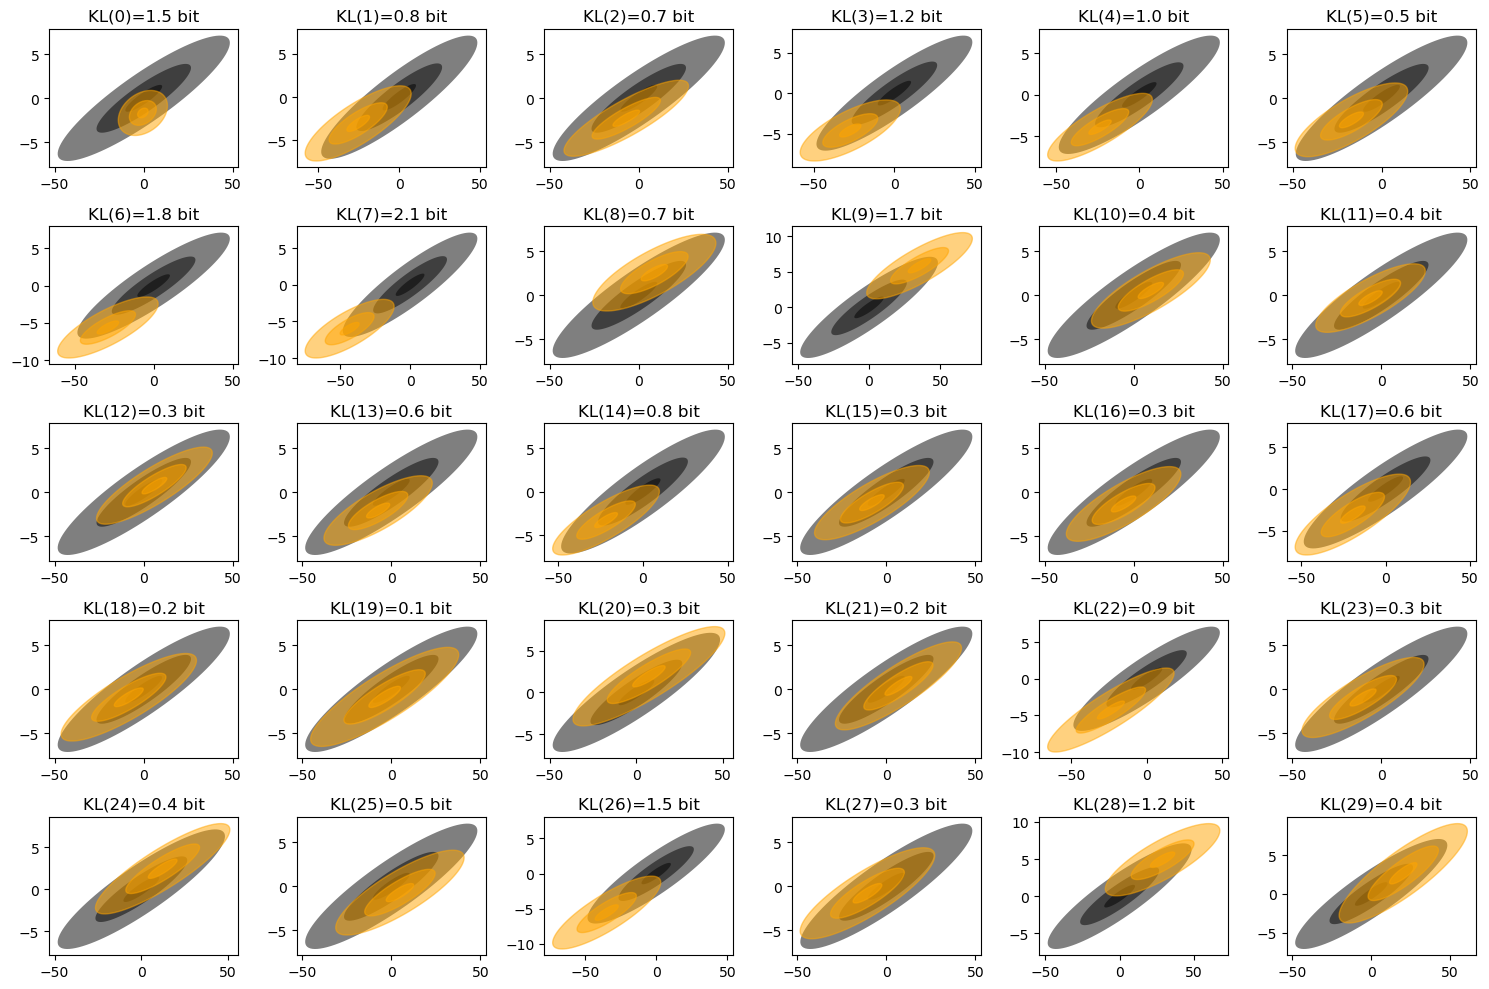

In [9]:
levels = [0.1, 0.5, 0.9]
n_cols = int(np.ceil(np.sqrt(_N_OBS_)))
n_rows = int(np.ceil(_N_OBS_ / n_cols))

plt.figure(figsize=(15, 10))

for obs in range(_N_OBS_):

    plt.subplot(n_rows, n_cols, obs + 1)
    
    for level in levels:
        draw_bridge_level(11, level, linestyle='', color='k', fill=True, alpha=0.5)
    
    for level in levels:
        draw_empirical_ellipsoid(action1_test[:, obs], action0_test[:, obs], level, color="orange", fill=True, alpha=0.5)

    # Condition actions on logl
    a1 = action1_test[:, obs]
    a0 = action0_test[:, obs]
    logl_ = np.array(logl_test)[:,1]
    logl_ -= logl_.max()
    p     = np.exp(logl_)
    p /= p.sum()
    indices = np.random.choice(len(logl_), size=10*len(logl_), p=p)

    #for level in levels:
    #    draw_empirical_ellipsoid(a1[indices], a0[indices], level, color="aqua", fill=False, alpha=1)
    
    
    kl_div = kl_divergence_from_samples(11, action1_test[:, obs], action0_test[:, obs])
    plt.title(f"KL({obs})={kl_div:.1f} bit")

plt.tight_layout()

#### Run a very high-resolution particle filter as reference (Optional)

In [10]:
super_res_pf = True

if super_res_pf:
    N_parts_test = 100000
    X0_test = (np.zeros((N_parts_test, 3)))
    params['RNG'] = crng()
    params['use_bridges'] = False
    params['output_bridge_parameters'] = True
    params['use_spread'] = False
    
    len_test_sr  = []
    rew_test_sr  = []
    logl_test_sr = []
    action0_test_sr = []
    action1_test_sr = []
    
    v_offsets = np.linspace(v_offset_min, v_offset_max, 100)
    
    for v_off in tqdm(v_offsets):
            params['sigma_observation'] = _SIG_OBS_
            params['logv'] = np.log(_GT_V_*v_off)
            params['RNG'].reroll()
            res = ParticleFilter(abp_logl, abp_sde, X0_test, Y0, params)
            action0_test_sr.append(res['streams']['bridge_slope'].squeeze()[0, :])
            action1_test_sr.append(res['streams']['bridge_slope'].squeeze()[1, :])
            logl_test_sr.append([v_off, res['logl']])
    
    action0_test_sr = np.stack(action0_test_sr)
    action1_test_sr = np.stack(action1_test_sr)

  0%|          | 0/100 [00:00<?, ?it/s]

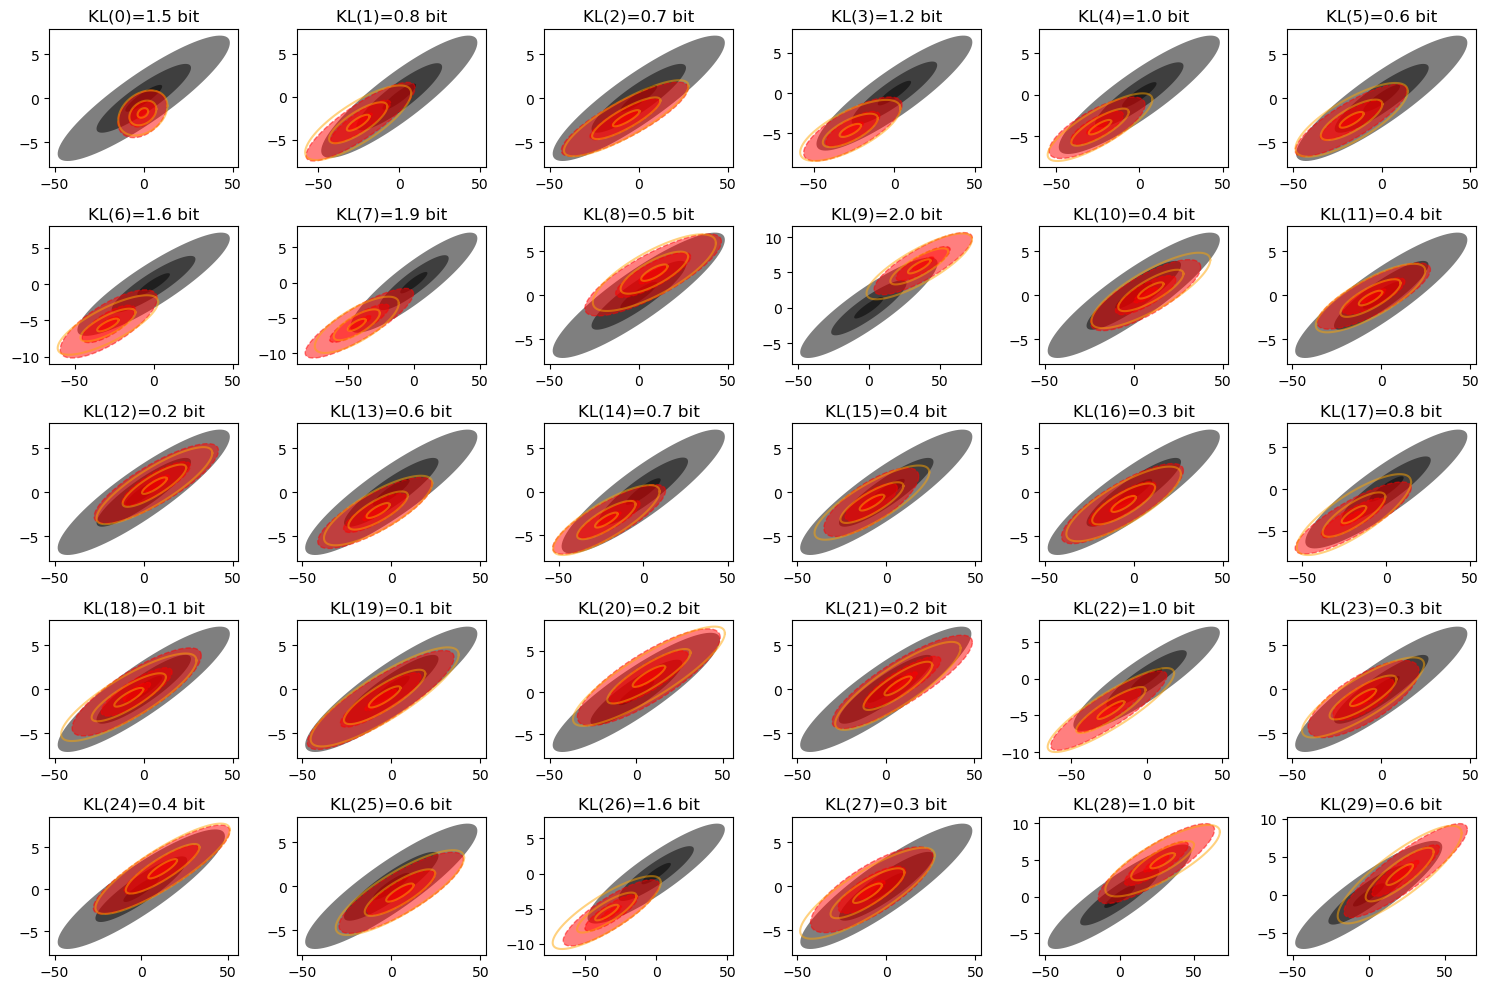

In [11]:
if super_res_pf:

    levels = [0.1, 0.5, 0.9]
    n_cols = int(np.ceil(np.sqrt(_N_OBS_)))
    n_rows = int(np.ceil(_N_OBS_ / n_cols))
    
    plt.figure(figsize=(15, 10))
    
    for obs in range(_N_OBS_):
    
        plt.subplot(n_rows, n_cols, obs + 1)
        
        for level in levels:
            draw_bridge_level(11, level, linestyle='', color='k', fill=True, alpha=0.5)

        for level in levels:
            draw_empirical_ellipsoid(action1_test_sr[:, obs], action0_test_sr[:, obs], level, linestyle='--', color="red", fill=True, alpha=0.5)
        
        for level in levels:
            draw_empirical_ellipsoid(action1_test[:, obs], action0_test[:, obs], level, color="orange", fill=False, alpha=0.5)

        

        kl_div = kl_divergence_from_samples(11, action1_test_sr[:, obs], action0_test_sr[:, obs])
        plt.title(f"KL({obs})={kl_div:.1f} bit")
    
    plt.tight_layout()

## Mean-Squared-Displacement

Max Lag: 2


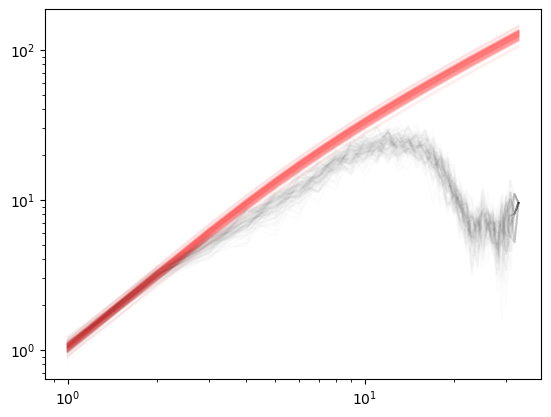

In [12]:
def TAMSD(X, Y, sigma=0, n_bootstrap_samples=1):

    X = X.flatten()
    Y = Y.flatten()

    n = len(X)  # Length of the trajectory
    tamsd_samples = np.zeros((n_bootstrap_samples, n - 1))

    for i in range(n_bootstrap_samples):
        # Add Gaussian noise to the trajectory
        X_noisy = X + np.random.normal(0, sigma, size=n)
        Y_noisy = Y + np.random.normal(0, sigma, size=n)

        for lag in range(1, n):
            displacements = (X_noisy[:-lag] - X_noisy[lag:])**2 + (Y_noisy[:-lag] - Y_noisy[lag:])**2
            displacements = np.random.choice(displacements, size=len(displacements))
            tamsd_samples[i, lag - 1] = np.mean(displacements)

    mean_tamsd = np.mean(tamsd_samples, axis=0)
    std_tamsd = np.std(tamsd_samples, axis=0)

    return mean_tamsd, std_tamsd


# BOOTSTRAP MSD
msd_V = []
max_lag = int(1 / _GT_DR_)
print("Max Lag:", max_lag)
def logBBP_MSD(lag, V0):
    DR = _GT_DR_
    return np.log(2*V0**2 / DR**2 * (DR * lag - 1 + np.exp(-DR * lag)) + 2*_SIG_OBS_**2)

for _ in range(100):
    X = OBS_X.flatten()
    Y = OBS_Y.flatten()
    n = len(OBS_X.flatten())
    X_noisy = X# + np.random.normal(0, _SIG_OBS_ * 1, size=n)
    Y_noisy = Y# + np.random.normal(0, _SIG_OBS_ * 1, size=n)
    tamsd, _ = TAMSD(X_noisy, Y_noisy)
    lags = (1 + np.arange(len(tamsd))) * _DT_OBS_
    plt.loglog(lags, tamsd, 'k', alpha=0.01)
    w = np.ones(n-1)
    w[max_lag:] = np.inf
    par, cov = curve_fit(logBBP_MSD, lags, np.log(tamsd), sigma=w)
    plt.plot(lags, np.exp(logBBP_MSD(lags, *par)), 'r', alpha=0.03)
    msd_V.append(par)
#print(par, cov)


#plt.plot(lags, BBP_MSD(lags, 1.1*_GT_V_), '--k')

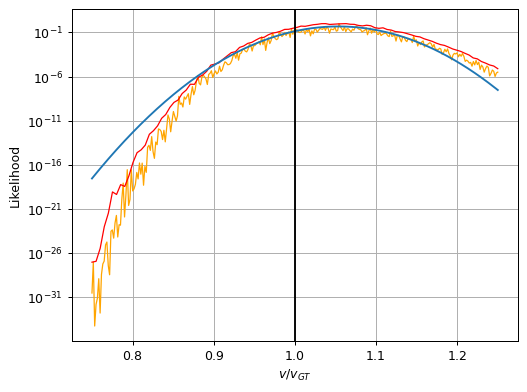

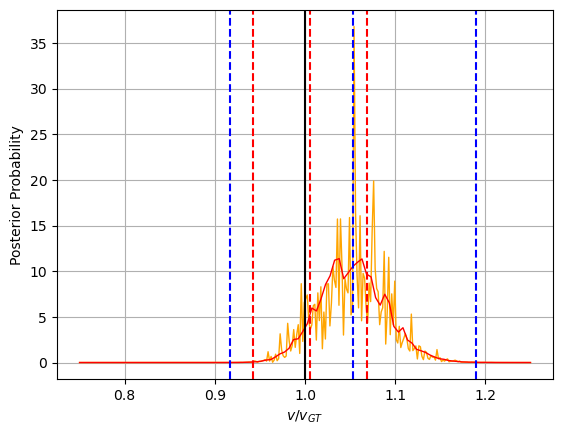

In [13]:
voff_ = np.array(logl_test)[:, 0]
logl_ = np.array(logl_test)[:, 1]

logl_ -= logl_.max()
lklhd_ = np.exp(logl_)

if super_res_pf:
    voff_sr = np.array(logl_test_sr)[:, 0]
    logl_sr = np.array(logl_test_sr)[:, 1]
    
    logl_sr -= logl_sr.max()
    lklhd_sr = np.exp(logl_sr)

weights = np.exp(logl_ - logl_.max())
def parabola(x,a,b,c):
    return a * x**2 + b * x + c

params_parabola, _ = curve_fit(parabola, voff_, logl_, sigma=1/weights, absolute_sigma=True)
a,b,c = params_parabola

mean_parabola = -b/(2*a)
std_parabola = np.sqrt(-1/(2*a))

plt.figure(dpi=90)
plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=1, c='orange')
if super_res_pf:
    plt.semilogy(voff_sr, lklhd_sr, alpha=1, label="Naive Particle Filter", lw=1, c='red')

plt.plot(voff_, np.exp(parabola(voff_, a, b, c)))
plt.xlabel(r"$v / v_{GT}$")
plt.ylabel("Likelihood")
plt.grid()
plt.axvline(1.0, c='k')
plt.show()
plt.plot(voff_, lklhd_ / np.trapz(lklhd_, voff_), alpha=1, lw=1, c='orange')
if super_res_pf:
    plt.plot(voff_sr, lklhd_sr / np.trapz(lklhd_sr, voff_sr), alpha=1, lw=1, c='red')
plt.xlabel(r"$v / v_{GT}$")
plt.ylabel("Posterior Probability")
plt.axvline(1.0, c='k')

search_size = 4 # Sigma

v_offset_min = mean_parabola - search_size*std_parabola
v_offset_max = mean_parabola + search_size*std_parabola

plt.axvline(mean_parabola, ls='--', c='b')
plt.axvline(v_offset_min, ls='--', c='b')
plt.axvline(v_offset_max, ls='--', c='b')

plt.axvline(np.mean(msd_V), ls='--', c='r')
plt.axvline(np.mean(msd_V) - 2 * np.std(msd_V), ls='--', c='r')
plt.axvline(np.mean(msd_V) + 2 * np.std(msd_V), ls='--', c='r')
plt.grid()




## Construct Agent

In [14]:
fresh_agent = True
train_agent = True
agent_name = "Vguide"

lr = 2e-3
hidden_layer_size = 16


if fresh_agent:
    Agent = PPO_Agent(2 * _FUTURES_ + 4, 2,
                      learning_rate=lr,
                      hidden_layer_size=hidden_layer_size,
                      #tensorboard_suffix=f'f{_FUTURES_}_h{hidden_layer_size}_lr_{lr}',
                      #name=agent_name,
                     )
    Agent.delete_tensorboard_data()
    Agent.gamma = 0.5
    Agent.relaxation = 0.5 / _SIG_OBS_

else:
    Agent = PPO_Agent.load(f"agents/{agent_name}")


params['Agent'] = Agent

total_steps = 0

No TensorBoard data found at runs/20241215-090331.


In [15]:
print(Agent.relaxation)

1.6666666666666667


In [16]:
params

{'RNG': <inference_tools_ppo.crng at 0x1635d2990>,
 'logDr': -0.6931471805599453,
 'logv': 0.22314355131420976,
 'dt': 0.1,
 'HilbertSort_dims': (0, 1),
 'HilbertSorter': <inference_tools_ppo.HilbertSorter at 0x150e698d0>,
 'sigma_observation': 0.3,
 'output_hires': False,
 'output_trajectory': True,
 'BridgeGen': <inference_tools_ppo.ConditionedBridge at 0x155718950>,
 'HilbertSort_useObservationCenter': False,
 'observation_parameters': [],
 'reward_range': 1e-15,
 'action_range0': 1.0,
 'action_range1': 1.0,
 'deterministic_agent': False,
 'provide_absolute_orientation': False,
 'provide_absolute_x_location': False,
 'provide_absolute_y_location': False,
 'provide_swarm_polarity': False,
 'base_on_last_observation': False,
 'use_bridge_offsets': False,
 'rotate_observations_to_swarm': True,
 'use_bridges': False,
 'output_bridge_parameters': True,
 'futures': 3,
 'use_spread': False,
 'Agent': <ppolib.PPO_Agent at 0x16420e610>}

In [17]:
#Agent.relaxation = 2.0

## Train Agent

In [18]:
N_parts = 4000
Agent.start_tensorboard_writer()
Agent.recording = False
Agent.awaiting_reward = False
params['deterministic_agent'] = False
params['RNG'] = crng()
params['use_bridges'] = True
params['use_spread'] = False

X0 = (np.zeros((N_parts, 3)))

len_run = []
rew_run = []
logl_run = []

n_training_steps = 200

relaxation_adoption = 0.9995

Agent.ent_coef = 0.15 # Start with more exploration
Agent.optimizer.param_groups[0]["lr"] = lr

full_length_achieved = False # Start without annealing, start when we first reached the entire trajectory length

if train_agent:
    try:
        for i in tqdm(range(n_training_steps)):
            
            params['sigma_observation'] = _SIG_OBS_ * Agent.relaxation
            Agent.start_recording()
            
            while len(Agent.obs) < 1024:
                v_offset = np.random.uniform(v_offset_min, v_offset_max)
                params['logv'] = np.log(_GT_V_*v_offset)
                params['additional_agent_information'] = [v_offset, np.log(Agent.relaxation)]
                params['RNG'].reroll()
                res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
                length = res['trajectory'].shape[1]
                
                if length >= _N_OBS_ or full_length_achieved:
                    Agent.relaxation *= relaxation_adoption
                    Agent.ent_coef = -0. # When swarm gets through all observations, deemphasize exploration
                    if Agent.relaxation < 1.0:
                        Agent.relaxation = 1.0
                    full_length_achieved = True
                else:
                    Agent.ent_coef = 0.15
                        
                len_run.append(length)
                rew_run.append([v_offset, res['total_reward_collected']])
                logl_run.append([v_offset, res['logl']])
    
            Agent.learn(minibatch_size=16, epochs=4)
            
            Agent.report_telemetry("target_precision", Agent.relaxation * _SIG_OBS_)
            Agent.report_telemetry("swarm_diversity", res['mean_diversity'])
            Agent.report_telemetry("swarm_diversity_min", res['min_diversity'] * N_parts)
            Agent.report_telemetry("action0_stress", res['action0_stress'])
            Agent.report_telemetry("action0_stress_max", res['action0_stress_max'])
            Agent.report_telemetry("action1_stress", res['action1_stress'])
            Agent.report_telemetry("action1_stress_max", res['action1_stress_max'])
            
            Agent.stop_recording()
            
            plt.plot(res['trajectory'][0,:], res['trajectory'][1,:], lw=2, ls='-', c='k')
            plt.plot(GT_X, GT_Y, '-', alpha=0.5)
            plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
            zoom_out = 5
            plt.xlim((OBS_X.min()-zoom_out, OBS_X.max()+zoom_out))
            plt.ylim((OBS_Y.min()-zoom_out, OBS_Y.max()+zoom_out))
            plt.title(f"{Agent.episode_count} episodes seen")
            #plt.savefig(f"img_11/guide2_{total_steps}.png")
            plt.close()
            total_steps += 1

    except KeyboardInterrupt:
        print("Bye!")

  0%|          | 0/200 [00:00<?, ?it/s]

In [19]:
if fresh_agent:
    Agent.save_model()

State saved to agents/20241215-090331.


Text(0, 0.5, 'Likelihood')

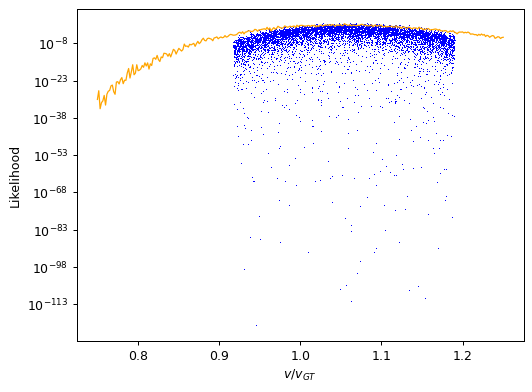

In [20]:
voff_b = np.array(logl_run)[:, 0]
logl_b = np.array(logl_run)[:, 1]

logl_b -= logl_b.max()
lklhd_b = np.exp(logl_b)


plt.figure(dpi=90)
colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
plt.semilogy(voff_b, lklhd_b, ',b', label="Naive Particle Filter", lw=1)
#plt.scatter(*np.array(logl_run).T, c=colors, s=1, alpha=0.51)
plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=1, c='orange')
plt.xlabel(r"$v / v_{GT}$")
plt.ylabel("Likelihood")

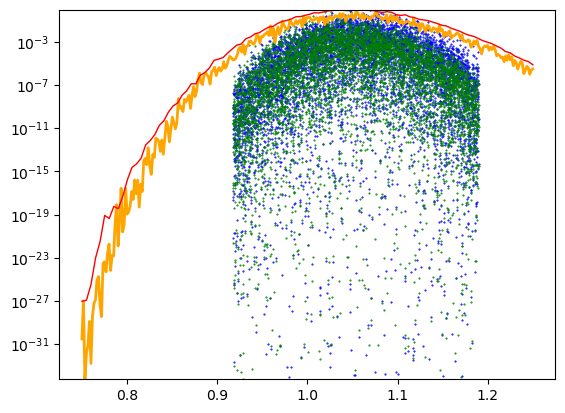

In [21]:
voff_b = np.array(rew_run)[:, 0]
rew_b = np.array(rew_run)[:, 1]

rew_b -= rew_b.max()
exprew_b = np.exp(-rew_b*np.log(params['reward_range']))

colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
plt.semilogy(voff_b, lklhd_b, '.', alpha=1, label="Bridged Likelihood", lw=1, c='blue', ms=1)
plt.semilogy(voff_b, exprew_b, '.', alpha=1, label="Bridged Reward", lw=1, c='green', ms=1)
plt.semilogy(voff_, lklhd_, alpha=1, label="Naive Particle Filter", lw=2, c='orange')
if super_res_pf:
    plt.semilogy(voff_sr, lklhd_sr, alpha=1, label="Naive Particle Filter", lw=1, c='red')
plt.ylim([lklhd_.min(), lklhd_.max()])
plt.show()

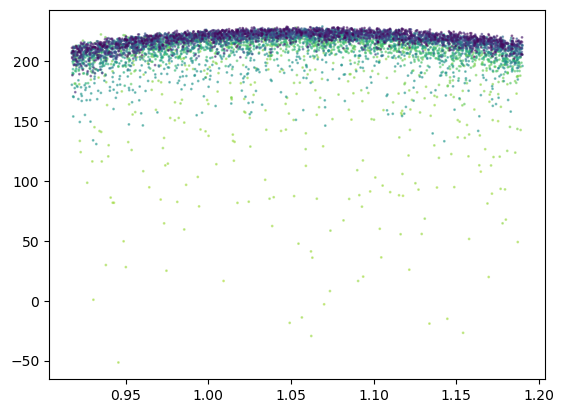

In [22]:
colors = plt.cm.viridis_r(np.linspace(0, 1, len(rew_run)))
plt.scatter(*np.array(logl_run).T, c=colors, s=1, alpha=0.51)
plt.show()

# Check Agent Performance

In [23]:
Agent.recording = False
Agent.awaiting_reward = False

len_test_B = []
rew_test_B = []
logl_test_B = []
rew_test_B = []
action0_test_B = []
action1_test_B = []

v_offsets = np.linspace(v_offset_min, v_offset_max, 300)

wobble_scale = 0.

params['offsetRNG'] = ZeroBasedRNG()

spread0, spread1 = np.exp(Agent.agent.actor_logstd.detach().numpy().flatten())


for v_off in tqdm(v_offsets):
        params['offsetRNG'].revert()
        params['offsetRNG'].reroll(0.)
        params['sigma_observation'] = Agent.relaxation * _SIG_OBS_
        params['logv'] = np.log(_GT_V_*v_off)
        params['additional_agent_information'] = [v_off, np.log(Agent.relaxation)]
        params['deterministic_agent'] = True
        params['use_bridges'] = True
        params['use_spread'] = False
        params['RNG'].reroll(),
        params['bridge_spread0'] = spread0,
        params['bridge_spread1'] = spread1
        res = ParticleFilter(abp_logl, abp_sde, X0, Y0, params)
        length = res['trajectory'].shape[1]
        len_test_B.append(length)
        logl_test_B.append([v_off, res['logl']])
        rew_test_B.append([v_off, res['total_reward_collected']])
        action0_test_B.append(res['streams']['bridge_slope'].squeeze()[0, :])
        action1_test_B.append(res['streams']['bridge_slope'].squeeze()[1, :])

action0_test_B = np.stack(action0_test_B)
action1_test_B = np.stack(action1_test_B)

  0%|          | 0/300 [00:00<?, ?it/s]

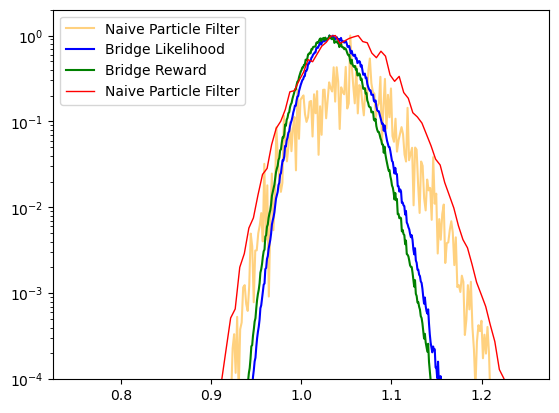

In [24]:
voff_ = np.array(logl_test)[:, 0]
logl_ = np.array(logl_test)[:, 1]
logl_ -= logl_.max()
lklhd_ = np.exp(logl_)

voff_B = np.array(logl_test_B)[:, 0]
logl_B = np.array(logl_test_B)[:, 1]
logl_B -= logl_B.max()
lklhd_B = np.exp(logl_B)


rew_B = np.array(rew_test_B)[:, 1]
rew_B -= rew_B.max()
exprew_B = np.exp(-rew_B*np.log(params['reward_range']))

plt.figure(dpi=100)
plt.plot(voff_, lklhd_, alpha=0.5, label="Naive Particle Filter", color="orange")
plt.semilogy(voff_B, lklhd_B, alpha=1, label="Bridge Likelihood", color="blue")
plt.semilogy(voff_B, exprew_B, alpha=1, label="Bridge Reward", color="green")

if super_res_pf:
    plt.semilogy(voff_sr, lklhd_sr, alpha=1, label="Naive Particle Filter", lw=1, c='red')
plt.legend()
plt.ylim([1e-4, 2e0])
plt.show()

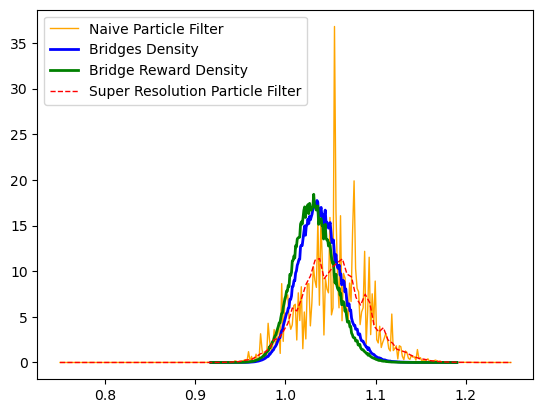

In [25]:
plt.plot(voff_, lklhd_ / np.trapz(lklhd_, voff_), alpha=1, label="Naive Particle Filter", lw=1, color="orange")
plt.plot(voff_B, lklhd_B / np.trapz(lklhd_B, voff_B), alpha=1, label="Bridges Density", lw=2, color="blue")
plt.plot(voff_B, exprew_B / np.trapz(exprew_B, voff_B), alpha=1, label="Bridge Reward Density", lw=2, color="green")
if super_res_pf:
    plt.plot(voff_sr, lklhd_sr / np.trapz(lklhd_sr, voff_sr), alpha=1, ls='--', lw=1, label='Super Resolution Particle Filter', c='red')
plt.legend()

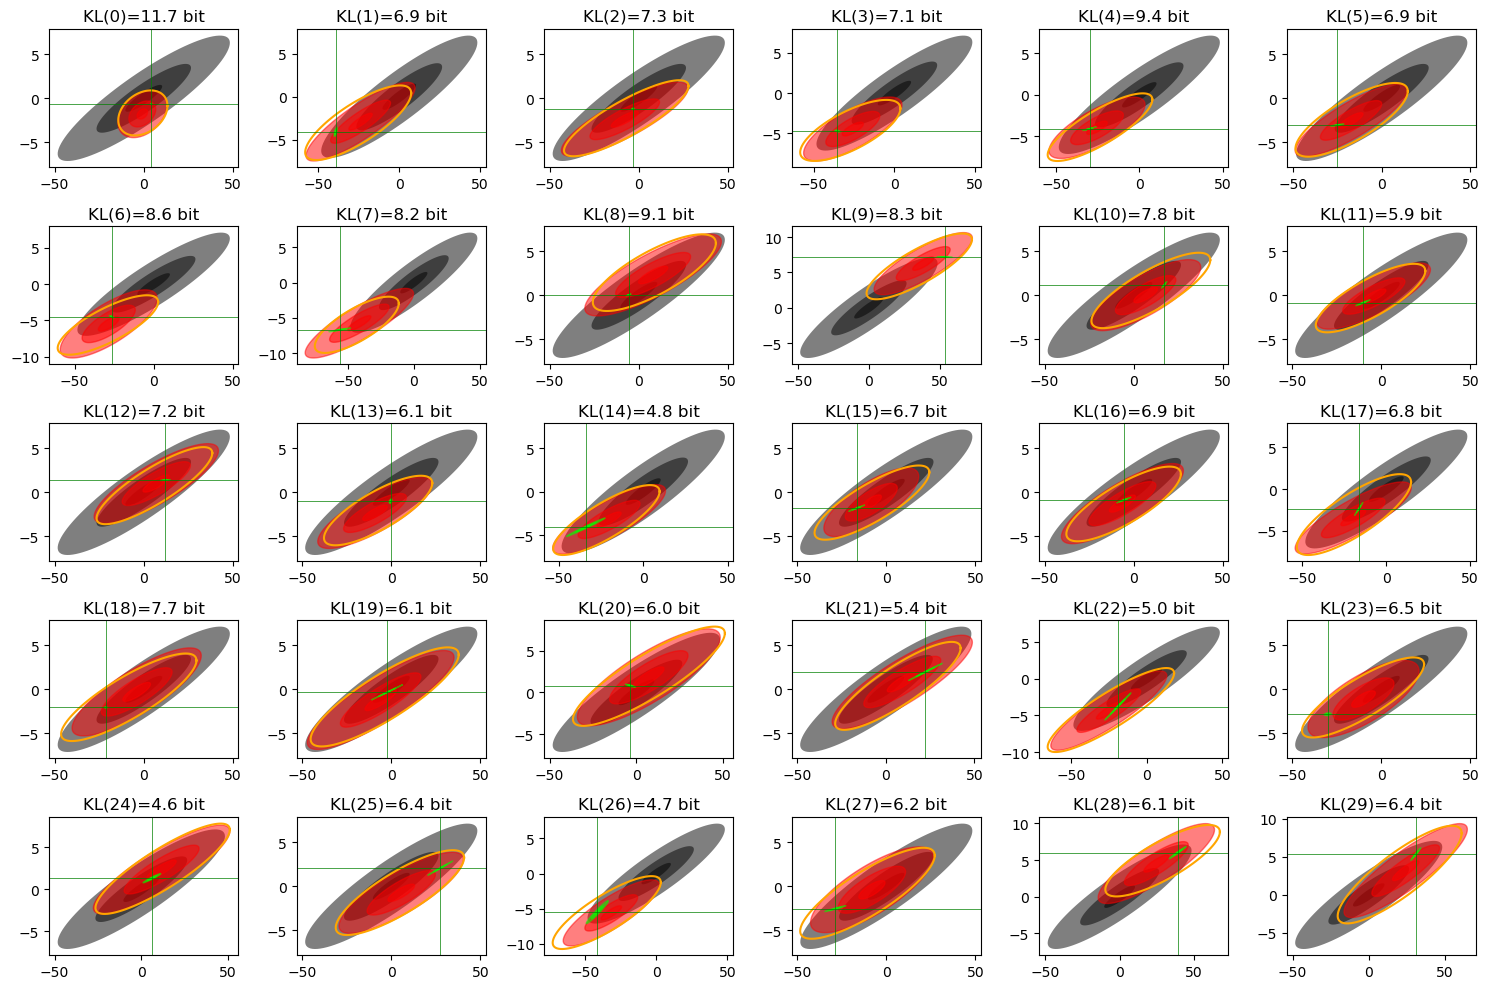

In [26]:
levels = [0.1, 0.5, 0.9]
n_cols = int(np.ceil(np.sqrt(_N_OBS_)))
n_rows = int(np.ceil(_N_OBS_ / n_cols))

plt.figure(figsize=(15, 10))

for obs in range(_N_OBS_):

    plt.subplot(n_rows, n_cols, obs + 1)
    
    for level in levels:
        draw_bridge_level(11, level, linestyle='', color='k', fill=True, alpha=0.5)

    if super_res_pf:
        for level in levels:
            draw_empirical_ellipsoid(action1_test_sr[:, obs], action0_test_sr[:, obs], level, color="red", fill=True, alpha=0.5)

    for level in levels[:1]:
        draw_empirical_ellipsoid(action1_test[:, obs], action0_test[:, obs], level, color="orange", fill=False, alpha=1)
    
    for level in levels:
        draw_empirical_ellipsoid(action1_test_B[:, obs], action0_test_B[:, obs], level, color="lime", fill=True, alpha=0.5)
    
    kl_div = kl_divergence_from_samples(11, action1_test_B[:, obs], action0_test_B[:, obs])
    plt.title(f"KL({obs})={kl_div:.1f} bit")

    plt.axvline(action1_test_B[:, obs].mean(), lw=0.5, c='green')
    plt.axhline(action0_test_B[:, obs].mean(), lw=0.5, c='green')

plt.tight_layout()

# Store results to scrapbook

In [27]:
mean, std, ci_mean, ci_std = bootstrap_mean_std(voff_, np.log(lklhd_))
res_pf = dict(mean=mean, std=std, ci_mean=ci_mean, ci_std=ci_std)
sb.glue("res_pf", res_pf)

mean, std, ci_mean, ci_std = bootstrap_mean_std(voff_B, np.log(lklhd_B))
res_B = dict(mean=mean, std=std, ci_mean=ci_mean, ci_std=ci_std)
sb.glue("res_B", res_B)

if super_res_pf:
    mean, std, ci_mean, ci_std = bootstrap_mean_std(voff_sr, np.log(lklhd_sr))
    res_sr = dict(mean=mean, std=std, ci_mean=ci_mean, ci_std=ci_std)
    sb.glue("res_sr", res_sr)

mean, std, ci_mean, ci_std = bootstrap_mean_std(voff_B, np.log(exprew_B))
res_rew = dict(mean=mean, std=std, ci_mean=ci_mean, ci_std=ci_std)
sb.glue("res_rew", res_rew)

res_MSD = dict(mean=np.mean(msd_V), std=np.std(msd_V))
sb.glue("res_MSD", res_MSD)